# Analiza hejtu ogólnego (final) – Q1(b): jak wygląda hejt w dyskusjach o migracji

Ten notebook jest **finalną wersją** analizy: liczby i wykresy z niego są w preprincie (folder `reports/final_gemini/`).
Liczy tak samo jak wcześniejsze notebooki, zmieniło się tylko **skąd bierzemy etykiety i ile jest wydarzeń**:

| | wcześniej | teraz (final) |
|---|---|---|
| wydarzenia | 7 (LLM) / 11 (HerBERT) | **20** |
| `hate_migrant`, `migrant` | LLM przez Ollamę (`labeled/`) | **Gemini 3.5 Flash-Lite** (`llm/`) |
| `hate` (hejt ogólny) | HerBERT (`herbert/`) | **Gemini** (`llm/`); HerBERT jako **sprawdzenie** |
| okno | −7…+14 dni | −7…+14 dni (bez zmian) |
| jednostka | komórka wydarzenie × platforma | bez zmian |

**Mianownik:** wszystkie komentarze komórki w oknie; komentarz, który nie przeszedł filtra tematycznego (nie trafił do Gemini), ma 0 dla każdej etykiety.
**Wersja danych:** każda komórka jest liczona na tej wersji `clean/`, na której puszczono Gemini (md5 z `dvc.lock`, plik z lokalnego cache DVC) – etykiety i komentarze zawsze do siebie pasują.

Ten sam kod jest w `scripts/final_analysis_gemini.py` (do odpalenia z terminala).

Ten notebook liczy **Q1(b)**: cechy komentarzy (słowa, forma, adresat, grupy) u komentarzy z hejtem (`hate`, Gemini) i bez, oraz regresję logistyczną hejtu na wszystkie cechy naraz (z osobnym poziomem bazowym dla każdej komórki, błędy klastrowane po wątkach; komentarze oznaczone słownikiem obelg są wyłączone z regresji). Tak samo jak `hate_analysis.ipynb`, tylko etykieta `hate` jest z Gemini zamiast z HerBERTa i jest 20 wydarzeń.

## 0. Konfiguracja

In [1]:
import gc
import json
import re
import sys
import warnings
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import yaml
from scipy import stats
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
OUT = ROOT / "reports" / "final_gemini"
OUT.mkdir(parents=True, exist_ok=True)
STEPS = {'q1b'}   # which parts this notebook computes

PLATFORMS = ["wykop", "youtube", "bluesky"]
PNAME = {"wykop": "Wykop", "youtube": "YouTube", "bluesky": "Bluesky"}
EVENTS = {  # folder: (English label, type)
    "2022-02-24_Atak_Rosji_Ukraina": ("Russian invasion of Ukraine", "war"),
    "2022-05-08_Zabojstwo_Nowy_Swiat": ("Murder in Warsaw", "disinformation"),
    "2023-09-22_Premiera_Zielona_Granica": ("Film Green Border", "political"),
    "2023-10-15_Referendum_Wybory": ("Election and referendum", "political"),
    "2024-04-10_Pakt_Azyl_PE": ("EU Pact adopted", "political"),
    "2024-05-28_Atak_Zolnierz_Granica": ("Attack on a soldier", "criminal"),
    "2024-06-06_Smierc_Zolnierza": ("Death of the soldier", "criminal"),
    "2024-09-08_Bojka_Srem": ("Brawl in Śrem", "criminal"),
    "2024-10-12_Strategia_Migracyjna": ("Migration strategy", "political"),
    "2024-12-20_Atak_Jarmark_Magdeburg": ("Magdeburg market attack", "criminal"),
    "2025-03-30_Dezinformacja_Wroclaw_Relokacja_Migrantow": ("Wrocław relocation hoax", "disinformation"),
    "2025-06-06_Naloty_ICE_Los_Angeles": ("ICE raids, LA", "political"),
    "2025-07-19_Protesty_Antyimigracyjne_Polska": ("Anti-migration protests", "political"),
    "2025-07-31_Dezinformacja_Swinoujscie_Autokar_Migranci": ("Świnoujście bus hoax", "disinformation"),
    "2025-10-15_Dezinformacja_Krakow": ("Kraków murder", "disinformation"),
    "2026-06-12_Pakt_Migracyjny_Wejscie_w_Zycie": ("EU Pact in force", "political"),
    "2026-07-11_Atak_Ukrainskie_Nastolatki_Bielsko_Biala": ("Bielsko-Biała attack", "criminal"),
    "2026-07-30_Ceuta_Masowe_Przekroczenie": ("Ceuta mass crossing", "border crisis"),
    "2026-08-15_Atak_Kamienna_Gora": ("Kamienna Góra attack", "criminal"),
    "2026-09-15_Atak_Jaroslaw": ("Jarosław attack", "criminal"),
}
TYPES = ["criminal", "political", "disinformation", "border crisis", "war"]
EXCLUDE = {("youtube", "2024-06-06_Smierc_Zolnierza")}   # the whole 'before' period is one video
WINDOW, MIN_N = (-7, 14), 30
MEAS = {"hate": "hate", "hate_migrant": "hate_migrant", "migrant": "migrant"}
MNAME = {"hate": "General hate (hate)", "hate_migrant": "Hate toward migrants (hate_migrant)",
         "migrant": "Comments about migration (migrant)"}
PCOL = {"wykop": "#2a78d6", "youtube": "#eb6834", "bluesky": "#1baf7a"}
TCOL = dict(zip(TYPES, ["#c2410c", "#7c3aed", "#0f766e", "#b45309", "#52514e"]))
INK, INK2, MUTED, HATE_C, NON_C = "#1a2233", "#52514e", "#8a8984", "#b4381f", "#9aa3ad"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 220, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})
R = {}   # results.json
if STEPS and (OUT / "results.json").exists():
    R = json.loads((OUT / "results.json").read_text(encoding="utf-8"))
ORDER = list(EVENTS)
LBL = {ev: v[0] for ev, v in EVENTS.items()}


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()


def jdump():
    (OUT / "results.json").write_text(json.dumps(R, indent=1, ensure_ascii=False, default=float), encoding="utf-8")

## Dane

In [2]:
# ---------------------------------------------------------------- 0. data -------------------------------------------
LOCK = yaml.safe_load((ROOT / "dvc.lock").read_text(encoding="utf-8"))["stages"]
CACHE = ROOT / ".dvc" / "cache" / "files" / "md5"


def cache_path(md5):
    p = CACHE / md5[:2] / md5[2:]
    return p if p.exists() else None


def llm_clean_file(platform, folder):
    """comments.csv of `clean` in the version the llm@ stage was run on (dvc.lock dep md5 -> local cache)."""
    for name, st in LOCK.items():
        if not name.startswith("llm@"):
            continue
        if not any(o["path"] == f"data/interim/{platform}/{folder}/llm" for o in st.get("outs", [])):
            continue
        dep = [d for d in st["deps"] if d["path"].endswith(f"{platform}/{folder}/clean")]
        if dep and (c := cache_path(dep[0]["md5"])):
            for f in json.loads(c.read_text()):
                if f["relpath"] == "comments.csv" and (p := cache_path(f["md5"])):
                    return p, dep[0]["md5"]
    return ROOT / "data" / "interim" / platform / folder / "clean" / "comments.csv", "workspace"


def as_bool(s):
    return s.astype(str).str.strip().isin(["1", "1.0", "True", "true"])


BASE_COLS = ["comment_id", "relative_day", "thread_id", "author_id", "likes", "replies", "text_raw"]


def load_cell(platform, folder):
    d = ROOT / "data" / "interim" / platform / folder
    lf = d / "llm" / "comments.csv"
    if not lf.exists():
        return None, None
    cf, ver = llm_clean_file(platform, folder)
    c = pd.read_csv(cf, encoding="utf-8-sig", usecols=lambda x: x in BASE_COLS,
                    dtype={"comment_id": str, "thread_id": str, "author_id": str, "text_raw": str})
    c = c.drop_duplicates("comment_id")
    n_all_period = len(c)
    c = c[c["relative_day"].between(*WINDOW)].copy()
    lab = pd.read_csv(lf, encoding="utf-8-sig", dtype=str).drop_duplicates("comment_id")
    # one older run of llm_classify.py used shorter column names
    lab = lab.rename(columns={"is_about_migration": "llm_is_about_migration", "hate": "llm_is_hate_general",
                              "hate_migrants": "llm_is_hate_migrants"})
    x = c.merge(lab[["comment_id", "text", "llm_is_about_migration", "llm_is_hate_general", "llm_is_hate_migrants",
                     "source"]], on="comment_id", how="left", indicator=True)
    topic = x.pop("_merge").eq("both")
    x["topic"] = topic
    x["migrant"] = topic & as_bool(x["llm_is_about_migration"])
    x["hate"] = topic & as_bool(x["llm_is_hate_general"])
    x["hate_migrant"] = topic & as_bool(x["llm_is_hate_migrants"])
    x["slur"] = topic & x["source"].eq("slur")
    # robustness: general hate from HerBERT-HS + slur dictionary (its own topic filter; other comments = 0)
    hf = d / "herbert" / "comments.csv"
    has_hb = hf.exists()
    if has_hb:
        hb = pd.read_csv(hf, encoding="utf-8-sig", usecols=["comment_id", "in_topic", "hate_final"], dtype=str)
        hb = hb[as_bool(hb["in_topic"]) & as_bool(hb["hate_final"])]
        x["hate_herbert"] = x["comment_id"].isin(set(hb["comment_id"]))
    else:
        x["hate_herbert"] = False
    x["po"] = (x["relative_day"] >= 0).astype(np.int8)
    x["platform"], x["event"] = platform, folder
    x["cell"] = f"{platform}:{folder}"
    x["thread"] = x["cell"] + ":" + x["thread_id"].astype(str)
    x["author"] = (x["author_id"] if platform == "wykop" else folder + ":" + x["author_id"].astype(str))
    x.loc[x["author_id"].isna(), "author"] = np.nan
    for col in ("likes", "replies"):
        x[col] = pd.to_numeric(x[col], errors="coerce") if col in x else np.nan
    info = {"platform": platform, "event": folder, "clean_version": ver, "comments_full_period": n_all_period,
            "comments_window": len(x), "topic_window": int(topic.sum()),
            "llm_rows_not_in_clean": int((~lab["comment_id"].isin(c["comment_id"])).sum()),
            "before": int((x["po"] == 0).sum()), "after": int((x["po"] == 1).sum()), "has_herbert": has_hb}
    keep_base = ["cell", "platform", "event", "thread", "author", "relative_day", "po", "likes", "replies",
                 "topic", "migrant", "hate", "hate_migrant", "slur", "hate_herbert"]
    base = x[keep_base].copy()
    tx = x.loc[topic, ["cell", "text"] + (["text_raw"] if "text_raw" in x else [])].copy()
    return base, (tx, info)


frames, texts, info = [], [], []
offset = 0
for p in PLATFORMS:
    for ev in EVENTS:
        if (p, ev) in EXCLUDE:
            continue
        b, rest = load_cell(p, ev)
        if b is None:
            continue
        tx, inf = rest
        # one global row index shared by the label frame and the text frame
        idx = pd.RangeIndex(offset, offset + len(b))
        tx.index = idx[np.flatnonzero(b["topic"].to_numpy())]
        b.index = idx
        offset += len(b)
        inf["in_analysis"] = bool(inf["before"] >= MIN_N and inf["after"] >= MIN_N)
        info.append(inf)
        frames.append(b)
        texts.append(tx)
        print(f"{p:8s} {ev[:45]:45s} window {inf['comments_window']:7,d}  topic {inf['topic_window']:6,d}  "
              f"pre/post {inf['before']}/{inf['after']}  clean={inf['clean_version'][:8]}  missing={inf['llm_rows_not_in_clean']}",
              flush=True)
df = pd.concat(frames)
TX = pd.concat(texts)
del frames, texts
gc.collect()
info = pd.DataFrame(info)
info.to_csv(OUT / "cells.csv", index=False)
for c in ["cell", "platform", "event", "thread", "author"]:
    df[c] = df[c].astype("category")
CELLS = [f"{r.platform}:{r.event}" for r in info.itertuples() if r.in_analysis]
HB_CELLS = {f"{r.platform}:{r.event}" for r in info.itertuples() if r.in_analysis and r.has_herbert}
df["in_analysis"] = df["cell"].isin(CELLS)
R["data"] = {
    "events": len(EVENTS),
    "comments_full_period": {p: int(info.loc[info.platform == p, "comments_full_period"].sum()) for p in PLATFORMS},
    "comments_window": {p: int(info.loc[info.platform == p, "comments_window"].sum()) for p in PLATFORMS},
    "topic_window": {p: int(info.loc[info.platform == p, "topic_window"].sum()) for p in PLATFORMS},
    "topic_share_range": {p: [float((info.topic_window / info.comments_window)[info.platform == p].min()),
                              float((info.topic_window / info.comments_window)[info.platform == p].max())]
                          for p in PLATFORMS},
    "cells_total": len(info), "cells_in_analysis": len(CELLS),
    "cells_by_platform": {p: sum(c.startswith(p) for c in CELLS) for p in PLATFORMS},
    "cells_excluded_small": [c for c in (info.platform + ":" + info.event) if c not in CELLS],
    "llm_rows_not_in_clean": int(info["llm_rows_not_in_clean"].sum()),
}
lv = df[df["topic"]].groupby("platform", observed=True)[["hate", "hate_migrant", "migrant"]].mean()
lv_all = df.groupby("platform", observed=True)[["hate", "hate_migrant", "migrant"]].mean()
R["levels_topic"] = {p: {k: float(lv.loc[p, k]) for k in lv.columns} for p in PLATFORMS}
R["levels_all"] = {p: {k: float(lv_all.loc[p, k]) for k in lv_all.columns} for p in PLATFORMS}
R["levels_herbert_all"] = {p: float(df.loc[df["cell"].isin(HB_CELLS) & (df["platform"] == p), "hate_herbert"].mean()) for p in PLATFORMS}
R["levels_gemini_all_hbcells"] = {p: float(df.loc[df["cell"].isin(HB_CELLS) & (df["platform"] == p), "hate"].mean()) for p in PLATFORMS}
R["n_labelled"] = {k: int(df[k].sum()) for k in ["hate", "hate_migrant", "migrant", "topic"]}
jdump()
print("data:", R["data"], flush=True)
A = df[df["in_analysis"]].copy()
A["cell"] = A["cell"].cat.remove_unused_categories()
del df
gc.collect()

wykop    2022-02-24_Atak_Rosji_Ukraina                 window  13,636  topic 11,394  pre/post 3561/10075  clean=29edb90c  missing=0


wykop    2022-05-08_Zabojstwo_Nowy_Swiat               window  10,286  topic  8,507  pre/post 3462/6824  clean=c8d95b16  missing=0


wykop    2023-09-22_Premiera_Zielona_Granica           window  12,413  topic  9,553  pre/post 4834/7579  clean=78c5763e  missing=0


wykop    2023-10-15_Referendum_Wybory                  window   9,533  topic  5,170  pre/post 2886/6647  clean=1ce72d10  missing=0


wykop    2024-04-10_Pakt_Azyl_PE                       window  10,412  topic  7,824  pre/post 3458/6954  clean=081ea2e9  missing=0


wykop    2024-05-28_Atak_Zolnierz_Granica              window  10,815  topic  8,899  pre/post 2862/7953  clean=f831a88a  missing=0


... (47 outputs left out)

bluesky  2026-08-15_Atak_Kamienna_Gora                 window   8,871  topic  2,268  pre/post 2780/6091  clean=85940947  missing=0


bluesky  2026-09-15_Atak_Jaroslaw                      window   9,025  topic  2,595  pre/post 3046/5979  clean=410d630f  missing=0


data: {'events': 20, 'comments_full_period': {'wykop': 443608, 'youtube': 2201843, 'bluesky': 252649}, 'comments_window': {'wykop': 337201, 'youtube': 2165242, 'bluesky': 148679}, 'topic_window': {'wykop': 228984, 'youtube': 388194, 'bluesky': 39619}, 'topic_share_range': {'wykop': [0.46607167662175303, 0.8492838850422081], 'youtube': [0.050536829864147335, 0.43773264951608903], 'bluesky': [0.05405405405405406, 0.40799086757990866]}, 'cells_total': 55, 'cells_in_analysis': 50, 'cells_by_platform': {'wykop': 20, 'youtube': 19, 'bluesky': 11}, 'cells_excluded_small': ['bluesky:2024-04-10_Pakt_Azyl_PE', 'bluesky:2024-05-28_Atak_Zolnierz_Granica', 'bluesky:2024-06-06_Smierc_Zolnierza', 'bluesky:2024-09-08_Bojka_Srem', 'bluesky:2024-10-12_Strategia_Migracyjna'], 'llm_rows_not_in_clean': 2419}


31

In [3]:
# ---------------------------------------------------------------- 1. cell effects -----------------------------------
def agg(d, y, by=("thread", "po")):
    a = d.groupby(list(by), observed=True)[y].agg(["sum", "size"]).reset_index()
    return a[a["size"] > 0]


def glm_or(a, X, groups):
    endog = np.c_[a["sum"].to_numpy(float), (a["size"] - a["sum"]).to_numpy(float)]
    return sm.GLM(endog, X, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": groups})


def logit_cluster(X, k, n, groups, iters=25):
    """Binomial logit (k successes of n) by IRLS, cluster-robust (CR1) standard errors; memory-light."""
    b = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(X @ b, -30, 30)))
        w = n * p * (1 - p)
        H = X.T @ (X * w[:, None])
        g = X.T @ (k - n * p)
        step = np.linalg.solve(H, g)
        b += step
        if np.max(np.abs(step)) < 1e-8:
            break
    p = 1 / (1 + np.exp(-np.clip(X @ b, -30, 30)))
    H = X.T @ (X * (n * p * (1 - p))[:, None])
    Hi = np.linalg.inv(H)
    G = int(groups.max()) + 1
    S = np.zeros((G, X.shape[1]))
    np.add.at(S, groups, X * (k - n * p)[:, None])
    c = G / (G - 1) * (len(k) - 1) / (len(k) - X.shape[1])
    V = c * Hi @ (S.T @ S) @ Hi
    return b, np.sqrt(np.diag(V))

## Komentarze z filtra tematycznego (z tekstem)

In [4]:
# ---------------------------------------------------------------- 6. Q1(a) hate toward migrants -----------------------
STOP = set("""a aby ach acz ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym być był była było były będzie będą cali cała cały
chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze dokąd dość
dużo dwa dziś dzisiaj gdy gdyby gdyż gdzie go i ich ile im inna inne inny innych iż ja ją jak jakaś jakby jaki jakie jakiś jako je jeden
jedna jedno jednak jego jej jemu jest jestem jeszcze jeśli jeżeli już każdy kiedy kilka kto ktoś która które którego której który
których którym którzy lecz lub ma mają mam mamy mało mi mimo między mną mnie mogą moja moje może można mój mu musi my na nad nam nami
nas nasi nasz nasza nasze naszego naszych nawet nic nich nie niech niego niej nigdy nim nimi niż no o od on ona one oni ono oraz oto
po pod podczas ponad ponieważ powinien powinni poza prawie przecież przed przez przy również sam sama są się sobie sobą swoje ta tak
taka taki takie także tam te tego tej temu ten teraz też to tobą tobie trzeba tu tutaj twoja twoje twój ty tych tylko tym u w wam was
wasz we według wiele wielu więc więcej wszyscy wszystkich wszystkie wszystko wtedy wy właśnie z za zawsze ze znowu znów żaden że żeby
tez juz sie ktory ktora ktore bylo byl beda bedzie moze takze zeby niz jakis jakies cos nikt mieć móc chcieć wiedzieć mówić czas rok
raz który swój wszystek inny jakiś cały http https www com xd xdd link user""".split())
TOK = re.compile(r"[a-ząćęłńóśźż]{3,}")


def build_tok():
    import simplemma
    cache = {}

    def lem(t):
        if t not in cache:
            cache[t] = simplemma.lemmatize(t, lang="pl").lower()
        return cache[t]
    stop = STOP | {lem(w) for w in STOP}

    def toks(text):
        return [w for w in (lem(t) for t in TOK.findall(str(text).lower())) if w not in stop and len(w) >= 3]
    return toks


def log_odds(c1, c2, prior, min_count=10):
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["word", "n_hate", "n_other", "z"]).sort_values("z", ascending=False)


TARGETS = {
    "Ukrainians": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|chachoł|chochoł|upadlin",
    "Muslims / Arabs": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|szariat|meczet",
    "Africans": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "migrants in general": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}


def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n


def top_share(x, q):
    x = np.sort(np.asarray(x, float))[::-1]
    return x[:max(1, int(np.ceil(q * len(x))))].sum() / x.sum()

In [5]:
# texts of the comments in the analysis window that passed the topic filter (row index = df index)
T = A.loc[A["topic"], ["cell", "platform", "event", "po", "migrant", "hate", "hate_migrant", "slur", "author",
                       "likes", "replies", "thread"]]
del A
gc.collect()
TX = TX.loc[T.index]
T["text"] = TX["text"].fillna("").astype(str)
if "text_raw" in TX and ("q1b" in STEPS or not STEPS):
    raw = TX["text_raw"]
    T["text_raw"] = raw.where(raw.notna() & (raw != ""), T["text"])
    del raw
else:
    T["text_raw"] = T["text"]
del TX
gc.collect()
toks = build_tok()

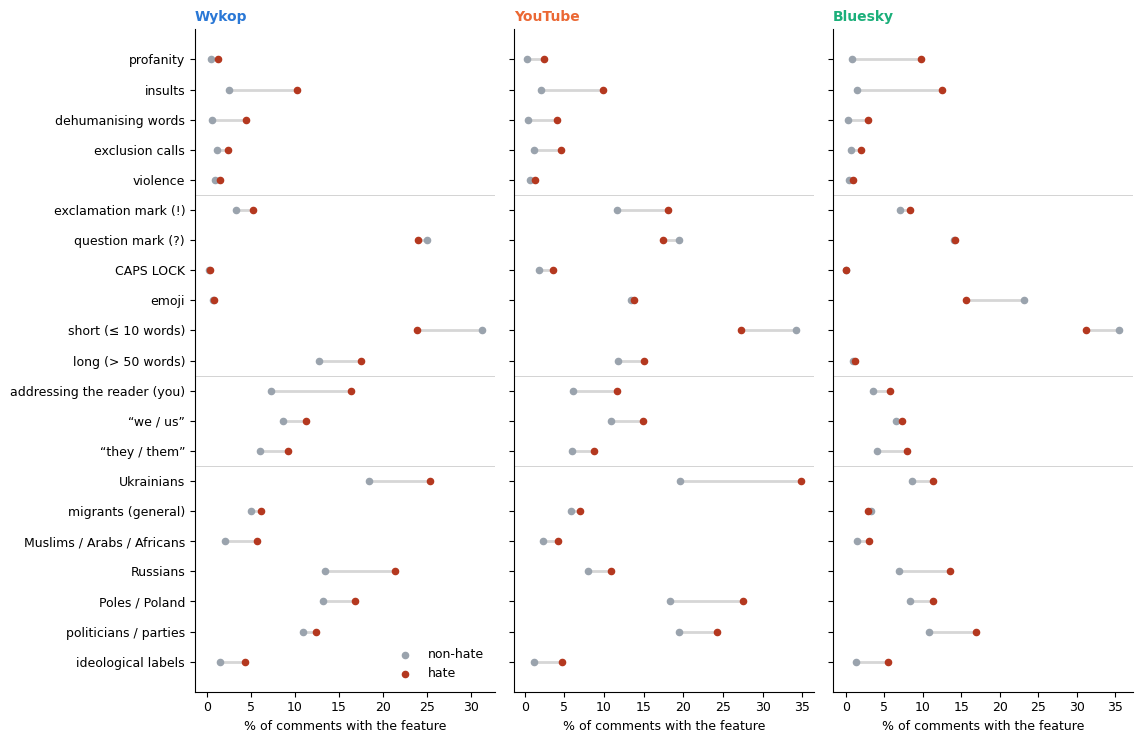

In [6]:
# ------------------------------------------------------------ 7. Q1(b) general hate: features -------------------
def rx(stems):
    body = "|".join(s[:-1] + r"(?!\w)" if s.endswith("$") else s for s in stems)
    return re.compile(rf"(?<!\w)(?:{body})", re.IGNORECASE)

LEX = {
    "profanity": rx(["kurw", "chuj", "huj", "pierdol", "pierdal", "jeba", "jebi", "jebn", "zajeb", "wyjeb", "pojeb", "pizd",
                     "skurw", "spierd", "wypierd", "zjeb", "dziwk"]),
    "insults": rx(["debil", "idiot", "kretyn", "głup", "durni", "dureń", "matoł", "baran", "osioł$", "kmiot", "tępak",
                   "tępy$", "tępe$", "upośledz", "imbecyl", "cymbał", "frajer", "szmat", "gnoj", "gówn"]),
    "dehumanising words": rx(["robactw", "robak", "szczur", "pasożyt", "zwierzęt", "zwierzę", "bydł", "ścierw", "gnid",
                              "małp", "szkodnik", "hołot", "dzicz", "dzikus", "bestia", "bestie$", "potwor", "śmieci$",
                              "śmieć$"]),
    "exclusion calls": rx(["wypierdal", "won$", "precz", "wracaj", "niech wracaj", "wracać do", "deport", "wyrzucić",
                           "wyrzucać", "wywalić", "odesłać", "wydalić", "wydalen", "zamknąć granic", "out$"]),
    "violence": rx(["zabić", "zabij", "rozstrzel", "powiesić", "powiesz", "wieszać", "spalić", "spalcie", "zastrzel",
                    "odstrzel", "utopić", "eksterminac", "wystrzelać", "wybić ich", "lać ich"]),
    "addressing the reader (you)": rx([w + "$" for w in ["ty", "cię", "ciebie", "tobie", "twój", "twoja", "twoje", "twoich",
                                                         "twoim", "wy", "was", "wam", "wasz", "wasza", "wasze", "waszych",
                                                         "jesteś", "jesteście"]]),
    "“we / us”": rx([w + "$" for w in ["my", "nas", "nam", "nasz", "nasza", "nasze", "naszych", "naszym", "naszej"]]),
    "“they / them”": rx([w + "$" for w in ["oni", "one", "nimi", "tacy", "takich", "tych ludzi", "ci ludzie"]]),
    "Ukrainians": rx(["ukrai", "ukraiń", "ukrop", "bander", "chachoł", "ukry$", "ukrów$", "ukrami$", "ukrom$", "upadlin"]),
    "migrants (general)": rx(["migran", "imigran", "emigran", "uchodź", "nachodź", "najeźdź", "przybysz", "nielegal", "azyl"]),
    "Muslims / Arabs / Africans": rx(["muzu", "muzułm", "islam", "arab", "allah", "ciap", "murzyn", "afryk", "czarnuch",
                                      "czarnoskór", "syryj", "afgań", "afgan", "talib", "szariat", "meczet", "turk", "turc"]),
    "Russians": rx(["rosj", "rosyj", "rusk", "kacap", "putin", "moskal", "onuc"]),
    "Poles / Poland": rx(["polak", "polac", "polsk", "polek"]),
    "politicians / parties": rx(["pis$", "pisu$", "pisie$", "pisow", "tusk", "kaczyń", "konfeder", "bosak", "mentzen",
                                 "platforma obywatel", "lewic", "rząd$", "rządu$", "rządzie$", "sejm", "polityk",
                                 "prezydent", "dud", "nawrock", "trzaskowsk", "minist", "ue$", "unii$", "unia$", "bruksel"]),
    "ideological labels": rx(["lewak", "lewact", "prawak", "katol", "faszyst", "nazist", "komuch", "tęczow", "lgbt",
                              "neomark", "pisior", "peowiec", "platfus", "kaczyst", "konfiarz", "ruska onuca"]),
}
EMOJI = re.compile("[\U0001F300-\U0001FAFF☀-➿]")
low = T["text"].str.lower()
F = pd.DataFrame({k: low.str.contains(r) for k, r in LEX.items()}, index=T.index)
letters = T["text_raw"].str.count(r"[A-Za-zĄĆĘŁŃÓŚŹŻąćęłńóśźż]")
upper = T["text_raw"].str.count(r"[A-ZĄĆĘŁŃÓŚŹŻ]")
F["exclamation mark (!)"] = T["text_raw"].str.contains("!", regex=False)
F["question mark (?)"] = T["text_raw"].str.contains("?", regex=False)
F["CAPS LOCK"] = (letters >= 8) & (upper / letters.clip(lower=1) >= 0.5)
F["emoji"] = T["text_raw"].str.contains(EMOJI)
T["n_words"] = T["text"].str.split().str.len().fillna(0)
F["short (≤ 10 words)"] = T["n_words"] <= 10
F["long (> 50 words)"] = T["n_words"] > 50
del low, letters, upper
T = T.drop(columns=["text_raw"])
gc.collect()
GROUPS = {"Language": ["profanity", "insults", "dehumanising words", "exclusion calls", "violence"],
          "Form": ["exclamation mark (!)", "question mark (?)", "CAPS LOCK", "emoji", "short (≤ 10 words)", "long (> 50 words)"],
          "Addressee": ["addressing the reader (you)", "“we / us”", "“they / them”"],
          "Groups": ["Ukrainians", "migrants (general)", "Muslims / Arabs / Africans", "Russians", "Poles / Poland",
                     "politicians / parties", "ideological labels"]}
order = [f for g in GROUPS.values() for f in g]
prof = {p: {h: (100 * F[(T.platform == p) & (T.hate == h)][order].mean()).to_dict() for h in (True, False)} for p in PLATFORMS}
R["q1b"] = {"n": len(T), "n_hate": int(T.hate.sum()), "profile": {p: {str(k): v for k, v in d.items()} for p, d in prof.items()},
            "median_words": {p: {"hate": float(T.loc[(T.platform == p) & T.hate, "n_words"].median()),
                                 "other": float(T.loc[(T.platform == p) & ~T.hate, "n_words"].median())} for p in PLATFORMS}}
fig, axes = plt.subplots(1, 3, figsize=(11.5, 0.3 * len(order) + 1.2), sharey=True)
yy = np.arange(len(order))[::-1]
for ax, p in zip(axes, PLATFORMS):
    h = np.array([prof[p][True][f] for f in order]); n = np.array([prof[p][False][f] for f in order])
    ax.hlines(yy, np.minimum(h, n), np.maximum(h, n), color="#d6d6d6", lw=2)
    ax.scatter(n, yy, color=NON_C, s=20, label="non-hate", zorder=3)
    ax.scatter(h, yy, color=HATE_C, s=20, label="hate", zorder=3)
    ax.set_yticks(yy, order); ax.set_title(PNAME[p], color=PCOL[p]); ax.set_xlabel("% of comments with the feature")
    cut = len(order)
    for g in list(GROUPS)[:-1]:
        cut -= len(GROUPS[g]); ax.axhline(cut - 0.5, color="#cccccc", lw=0.6)
axes[0].legend(loc="lower right")
plt.tight_layout()
save(fig, "ha_2_profile")

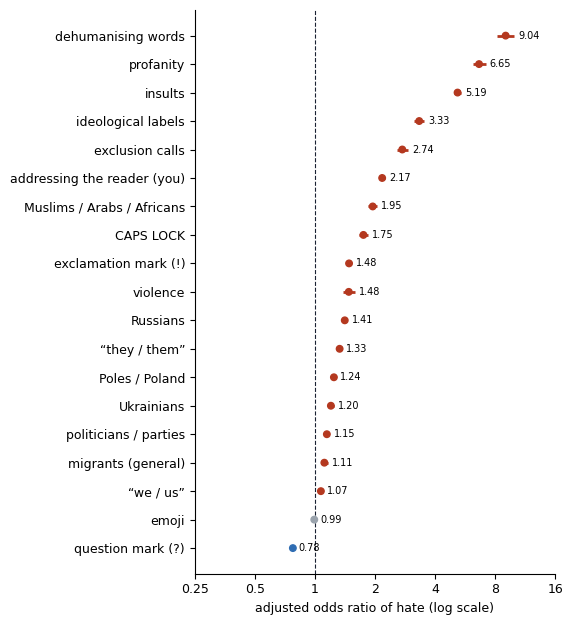

Q1b done


In [7]:
# logistic regression (slur-labelled comments excluded), aggregated over identical rows for speed
regf = [f for f in order if f not in ("short (≤ 10 words)", "long (> 50 words)")]
M = F.loc[~T["slur"], regf].astype(np.int8)
M.columns = [f"x{i}" for i in range(len(regf))]
M["lw"] = np.round(np.log1p(T.loc[~T["slur"], "n_words"]), 1)
M["cell"] = T.loc[~T["slur"], "cell"].cat.codes.values
M["thread"] = T.loc[~T["slur"], "thread"].cat.codes.values
M["y"] = T.loc[~T["slur"], "hate"].astype(int).values
keys = [c for c in M.columns if c != "y"]
a = M.groupby(keys, observed=True)["y"].agg(["sum", "size"]).reset_index()
X = a[[f"x{i}" for i in range(len(regf))] + ["lw"]].astype(float)
X = pd.concat([X, pd.get_dummies(a["cell"].astype(str), prefix="c", drop_first=True, dtype=float)], axis=1)
X = sm.add_constant(X)
del M, F, T
gc.collect()
names = list(X.columns)
Xa = X.to_numpy(np.float64)
del X
gc.collect()
b, se = logit_cluster(Xa, a["sum"].to_numpy(float), a["size"].to_numpy(float), pd.factorize(a["thread"])[0])
del Xa
pos = {n: i for i, n in enumerate(names)}

def row(lbl, key):
    bb, ss = b[pos[key]], se[pos[key]]
    return (lbl, np.exp(bb), np.exp(bb - 1.96 * ss), np.exp(bb + 1.96 * ss), 2 * stats.norm.sf(abs(bb / ss)))
orr = pd.DataFrame([row(regf[i], f"x{i}") for i in range(len(regf))] + [row("log(number of words)", "lw")],
                   columns=["feature", "OR", "lo", "hi", "p"]).set_index("feature")
orr.to_csv(OUT / "logit_features.csv")
R["q1b"]["logit"] = orr.to_dict("index")
R["q1b"]["logit_n"] = int(a["size"].sum())
o = orr.drop(index="log(number of words)").sort_values("OR")
fig, ax = plt.subplots(figsize=(5.8, 0.28 * len(o) + 1))
yy = np.arange(len(o))
c = [HATE_C if lo > 1 else ("#2f6db3" if hi < 1 else NON_C) for lo, hi in zip(o["lo"], o["hi"])]
ax.hlines(yy, o["lo"], o["hi"], color=c, lw=2); ax.scatter(o["OR"], yy, color=c, s=22, zorder=3)
ax.axvline(1, color=INK, ls="--", lw=0.8); ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8, 16], ["0.25", "0.5", "1", "2", "4", "8", "16"]); ax.minorticks_off()
ax.set_yticks(yy, o.index)
for yi, (v, hi) in enumerate(zip(o["OR"], o["hi"])):
    ax.text(hi * 1.05, yi, f"{v:.2f}", va="center", fontsize=7)
ax.set_xlabel("adjusted odds ratio of hate (log scale)")
plt.tight_layout()
save(fig, "ha_4_logit")
jdump()
print("Q1b done", flush=True)

In [8]:
print(pd.DataFrame(R["q1b"]["logit"]).T.round(3).sort_values("OR", ascending=False))

                                OR     lo     hi      p
dehumanising words           9.037  8.193  9.969  0.000
profanity                    6.649  6.166  7.169  0.000
insults                      5.188  4.998  5.386  0.000
ideological labels           3.332  3.140  3.536  0.000
exclusion calls              2.741  2.568  2.925  0.000
addressing the reader (you)  2.173  2.109  2.238  0.000
Muslims / Arabs / Africans   1.948  1.850  2.051  0.000
CAPS LOCK                    1.750  1.664  1.841  0.000
exclamation mark (!)         1.483  1.446  1.521  0.000
violence                     1.478  1.375  1.588  0.000
Russians                     1.411  1.368  1.456  0.000
“they / them”                1.330  1.294  1.366  0.000
Poles / Poland               1.245  1.217  1.273  0.000
Ukrainians                   1.202  1.163  1.243  0.000
politicians / parties        1.147  1.114  1.182  0.000
migrants (general)           1.115  1.067  1.164  0.000
“we / us”                    1.071  1.045  1.098